# Student Depression Dataset — Advanced Exploratory Data Analysis

**Dataset:** `Student_Depression_Dataset.csv` (27,901 records × 18 features)
**Target variable:** `Depression` (binary: 1 = depressed, 0 = not depressed)

This notebook performs a comprehensive EDA covering:

1. Environment setup & data loading
2. Structural overview & data quality audit
3. Data cleaning & type correction
4. Target variable analysis
5. Univariate analysis (numerical + categorical)
6. Bivariate analysis vs. target (statistical tests included)
7. Correlation & association analysis (Pearson + Cramér's V)
8. Outlier detection (IQR + Z-score)
9. Multivariate analysis & interaction effects
10. Feature engineering exploration
11. Quick predictive signal check (feature importance)
12. Key findings & summary

> **Note on subject matter:** this dataset covers self-reported depression and suicidal ideation among students, used here strictly for statistical/academic analysis. If this topic is personally relevant to you or someone you know, resources such as crisis helplines are available — happy to share them on request.


## 1. Environment Setup & Data Loading

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, pointbiserialr, mannwhitneyu
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_STATE = 42


In [2]:

DATA_PATH = "Student_Depression_Dataset.csv"
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Shape: 27,901 rows x 18 columns


,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


## 2. Structural Overview & Data Quality Audit

Establish dtypes, memory footprint, uniqueness, missingness, and duplication before any transformation.

In [3]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  str    
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  str    
 4   Profession                             27901 non-null  str    
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  str    
 11  Dietary Habit

In [4]:

overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(3),
    "example_value": df.iloc[0]
})
overview


,dtype,n_unique,n_missing,pct_missing,example_value
id,int64,27901,0,0.000,2
Gender,str,2,0,0.000,Male
Age,float64,34,0,0.000,33.0
City,str,52,0,0.000,Visakhapatnam
Profession,str,14,0,0.000,Student
Academic Pressure,float64,6,0,0.000,5.0
Work Pressure,float64,3,0,0.000,0.0
CGPA,float64,332,0,0.000,8.97
Study Satisfaction,float64,6,0,0.000,2.0
Job Satisfaction,float64,5,0,0.000,0.0


In [5]:

# Exact duplicate rows
n_dupes = df.duplicated().sum()
print(f"Fully duplicated rows: {n_dupes}")

# 'id' should be a unique identifier — verify
print(f"Unique ids: {df['id'].nunique()} / {len(df)} rows -> "
      f"{'OK, id is a valid primary key' if df['id'].nunique()==len(df) else 'WARNING: id has duplicates'}")


Fully duplicated rows: 0
Unique ids: 27901 / 27901 rows -> OK, id is a valid primary key


In [6]:

df.describe(include="number").T


,count,mean,std,min,25%,50%,75%,max
id,27901.0,70442.149421,40641.175216,2.0,35039.00,70684.00,105818.00,140699.0
Age,27901.0,25.822300,4.905687,18.0,21.00,25.00,30.00,59.0
Academic Pressure,27901.0,3.141214,1.381465,0.0,2.00,3.00,4.00,5.0
Work Pressure,27901.0,0.000430,0.043992,0.0,0.00,0.00,0.00,5.0
CGPA,27901.0,7.656104,1.470707,0.0,6.29,7.77,8.92,10.0
Study Satisfaction,27901.0,2.943837,1.361148,0.0,2.00,3.00,4.00,5.0
Job Satisfaction,27901.0,0.000681,0.044394,0.0,0.00,0.00,0.00,4.0
Work/Study Hours,27901.0,7.156984,3.707642,0.0,4.00,8.00,10.00,12.0
Financial Stress,27898.0,3.139867,1.437347,1.0,2.00,3.00,4.00,5.0
Depression,27901.0,0.585499,0.492645,0.0,0.00,1.00,1.00,1.0


In [7]:

df.describe(include="object").T


,count,unique,top,freq
Gender,27901,2,Male,15547
City,27901,52,Kalyan,1570
Profession,27901,14,Student,27870
Sleep Duration,27901,5,Less than 5 hours,8310
Dietary Habits,27901,4,Unhealthy,10317
Degree,27901,28,Class 12,6080
Have you ever had suicidal thoughts ?,27901,2,Yes,17656
Family History of Mental Illness,27901,2,No,14398


## 3. Data Cleaning & Type Correction

Findings to address:
- `Financial Stress` has a handful of missing values.
- `Sleep Duration` is a categorical bucket stored as a messy string (`'5-6 hours'`, `"'Less than 5 hours'"`, `'Others'`) — needs standardizing and, optionally, an ordinal mapping.
- `City` and `Profession` may contain noisy / nonsensical entries (this dataset is known to have a few garbage city names such as numeric strings) — check and isolate them rather than silently dropping.
- `Degree` has 20 raw categories that can be grouped by education level for cleaner analysis.
- Binary Yes/No text columns should be encoded for statistical testing.


In [8]:

# --- Missing values in Financial Stress ---
print(df["Financial Stress"].isna().sum(), "missing rows in 'Financial Stress'")
print(df.loc[df["Financial Stress"].isna()])


3 missing rows in 'Financial Stress'
          id  Gender   Age       City Profession  Academic Pressure  Work Pressure  CGPA  Study Satisfaction  Job Satisfaction  \
4458   22377  Female  32.0   Varanasi    Student                3.0            0.0  5.64                 1.0               0.0   
13596  68910    Male  29.0  Hyderabad    Student                2.0            0.0  8.94                 3.0               0.0   
19266  97610  Female  20.0    Kolkata    Student                1.0            0.0  6.83                 1.0               0.0   

          Sleep Duration Dietary Habits Degree Have you ever had suicidal thoughts ?  Work/Study Hours  Financial Stress  \
4458           5-6 hours        Healthy    BCA                                    No              12.0               NaN   
13596  Less than 5 hours      Unhealthy   B.Ed                                    No              12.0               NaN   
19266          5-6 hours        Healthy   MBBS                        

In [9]:

# Financial Stress is ordinal (1-5); impute missing with the mode (robust, preserves distribution shape for a handful of rows)
mode_val = df["Financial Stress"].mode()[0]
df["Financial Stress"] = df["Financial Stress"].fillna(mode_val)
print(f"Imputed {df['Financial Stress'].isna().sum()} remaining NaNs with mode = {mode_val}")


Imputed 0 remaining NaNs with mode = 5.0


In [10]:

# --- Audit 'City' for garbage / non-city entries ---
city_counts = df["City"].value_counts()
suspicious_cities = [c for c in city_counts.index if any(ch.isdigit() for ch in str(c)) or len(str(c)) <= 2]
print("Suspicious 'City' values:", suspicious_cities)
city_counts.loc[suspicious_cities] if suspicious_cities else "None found"


Suspicious 'City' values: ['3.0', 'Less than 5 Kalyan', 'ME']


City
3.0                   1
Less than 5 Kalyan    1
ME                    1
Name: count, dtype: int64

In [11]:

# --- Audit 'Profession' — dataset is meant to be students, check for leakage/noise ---
print(df["Profession"].value_counts())


Profession
Student                   27870
Architect                     8
Teacher                       6
Digital Marketer              3
Content Writer                2
Chef                          2
Doctor                        2
Pharmacist                    2
Civil Engineer                1
UX/UI Designer                1
Educational Consultant        1
Manager                       1
Lawyer                        1
Entrepreneur                  1
Name: count, dtype: int64


In [12]:

# --- Standardize Sleep Duration into an ordered category ---
sleep_map_order = ["Less than 5 hours", "5-6 hours", "7-8 hours", "More than 8 hours", "Others"]
df["Sleep Duration"] = df["Sleep Duration"].str.replace("'", "", regex=False).str.strip()
print(df["Sleep Duration"].value_counts())

sleep_ordinal = {"Less than 5 hours": 0, "5-6 hours": 1, "7-8 hours": 2, "More than 8 hours": 3, "Others": np.nan}
df["Sleep_Duration_Ordinal"] = df["Sleep Duration"].map(sleep_ordinal)


Sleep Duration
Less than 5 hours    8310
7-8 hours            7346
5-6 hours            6183
More than 8 hours    6044
Others                 18
Name: count, dtype: int64


In [13]:

# --- Group Degree into broader education levels for readability ---
def bucket_degree(deg):
    deg = str(deg)
    if deg == "Class 12":
        return "High School"
    if deg.startswith("B") or deg in ["LLB"]:
        return "Bachelor's"
    if deg.startswith("M"):
        return "Master's"
    if deg == "PhD":
        return "Doctorate"
    return "Other"

df["Degree_Level"] = df["Degree"].apply(bucket_degree)
df["Degree_Level"].value_counts()


Degree_Level
Bachelor's     12639
Master's        8143
High School     6080
Doctorate        522
Other            517
Name: count, dtype: int64

In [14]:

# --- Binary encode Yes/No + Gender for statistical tests ---
binary_maps = {
    "Have you ever had suicidal thoughts ?": {"Yes": 1, "No": 0},
    "Family History of Mental Illness": {"Yes": 1, "No": 0},
    "Gender": {"Male": 0, "Female": 1},
}
for col, mapping in binary_maps.items():
    df[col + "_enc"] = df[col].map(mapping)

df[["Have you ever had suicidal thoughts ?", "Have you ever had suicidal thoughts ?_enc",
    "Family History of Mental Illness", "Family History of Mental Illness_enc",
    "Gender", "Gender_enc"]].head()


,Have you ever had suicidal thoughts ?,Have you ever had suicidal thoughts ?_enc,Family History of Mental Illness,Family History of Mental Illness_enc,Gender,Gender_enc
0,Yes,1,No,0,Male,0
1,No,0,Yes,1,Female,1
2,No,0,Yes,1,Male,0
3,Yes,1,Yes,1,Female,1
4,Yes,1,No,0,Female,1


In [15]:

numeric_cols = ["Age", "Academic Pressure", "Work Pressure", "CGPA", "Study Satisfaction",
                "Job Satisfaction", "Work/Study Hours", "Financial Stress"]
categorical_cols = ["Gender", "City", "Profession", "Sleep Duration", "Dietary Habits",
                    "Degree", "Degree_Level", "Have you ever had suicidal thoughts ?",
                    "Family History of Mental Illness"]
target = "Depression"

print("Numeric features:", numeric_cols)
print("Categorical features:", categorical_cols)
print("Target:", target)


Numeric features: ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours', 'Financial Stress']
Categorical features: ['Gender', 'City', 'Profession', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Degree_Level', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']
Target: Depression


## 4. Target Variable Analysis — `Depression`

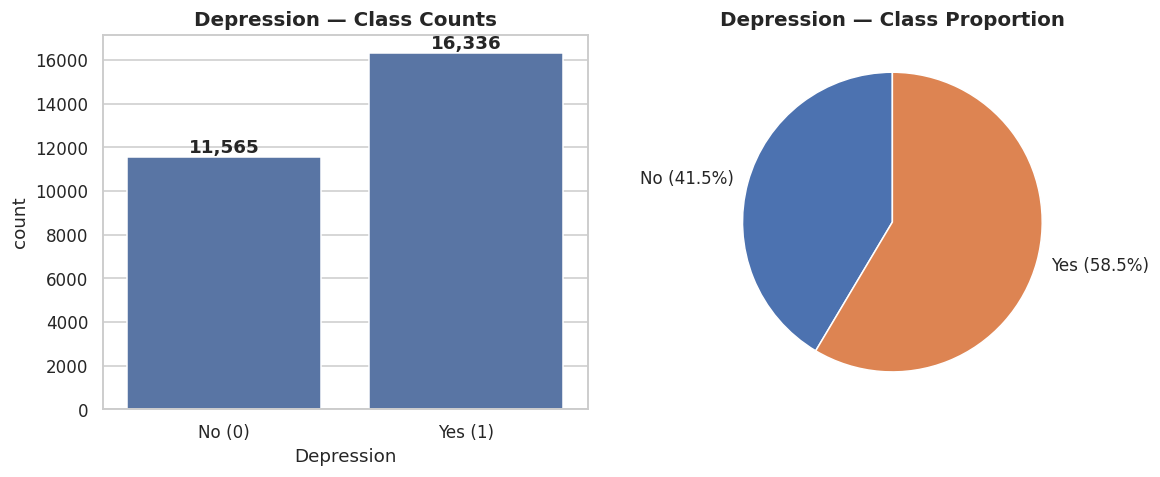

Depression
0    11565
1    16336
Name: count, dtype: int64
Depression
0    41.45
1    58.55
Name: proportion, dtype: float64

Class imbalance ratio (majority:minority): 1.41 : 1


In [16]:

target_counts = df[target].value_counts().sort_index()
target_pct = df[target].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.countplot(x=target, data=df, ax=ax[0])
ax[0].set_title("Depression — Class Counts")
ax[0].set_xticklabels(["No (0)", "Yes (1)"])
for i, v in enumerate(target_counts):
    ax[0].text(i, v + 200, f"{v:,}", ha="center", fontweight="bold")

ax[1].pie(target_pct, labels=[f"No ({target_pct[0]:.1f}%)", f"Yes ({target_pct[1]:.1f}%)"],
          autopct=None, startangle=90, colors=sns.color_palette("deep")[:2],
          wedgeprops={"edgecolor": "white"})
ax[1].set_title("Depression — Class Proportion")
plt.tight_layout()
plt.show()

print(target_counts)
print(target_pct.round(2))
print("\nClass imbalance ratio (majority:minority):",
      round(target_counts.max() / target_counts.min(), 2), ": 1")


**Observation:** the classes are only mildly imbalanced, so accuracy-based metrics later on would remain reasonably informative, but F1/AUC are still recommended for any downstream modeling.

## 5. Univariate Analysis — Numerical Features

For each numerical feature: distribution shape, skewness/kurtosis, and boxplot for spread/outlier visibility.

In [17]:

skew_kurt = pd.DataFrame({
    "mean": df[numeric_cols].mean(),
    "median": df[numeric_cols].median(),
    "std": df[numeric_cols].std(),
    "skew": df[numeric_cols].skew(),
    "kurtosis": df[numeric_cols].kurtosis(),
}).round(3)
skew_kurt


,mean,median,std,skew,kurtosis
Age,25.822,25.00,4.906,0.132,-0.846
Academic Pressure,3.141,3.00,1.381,-0.135,-1.161
Work Pressure,0.000,0.00,0.044,108.594,12110.636
CGPA,7.656,7.77,1.471,-0.113,-1.023
Study Satisfaction,2.944,3.00,1.361,0.010,-1.223
Job Satisfaction,0.001,0.00,0.044,74.106,5926.997
Work/Study Hours,7.157,8.00,3.708,-0.455,-1.000
Financial Stress,3.140,3.00,1.437,-0.130,-1.325


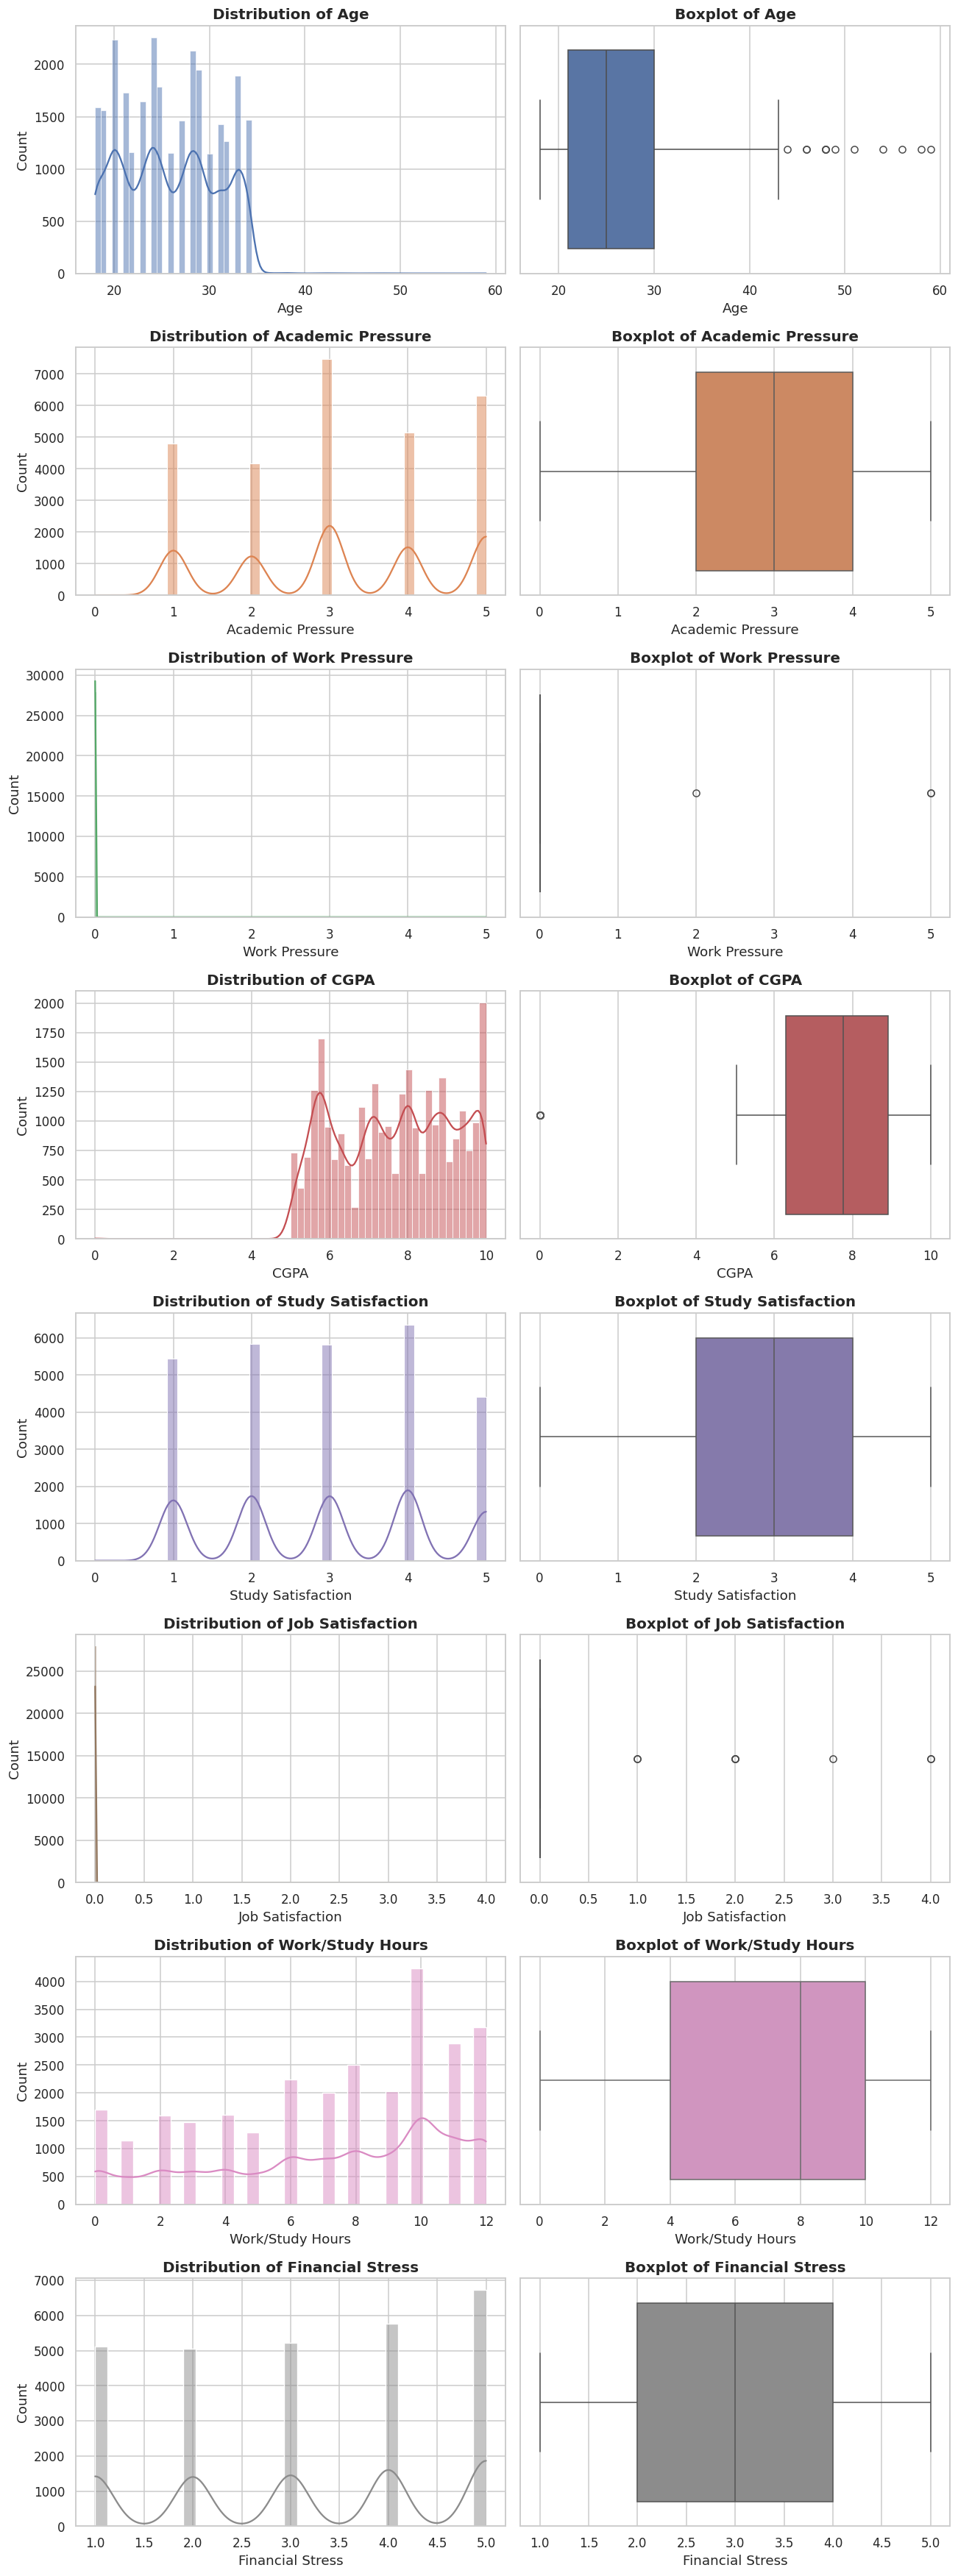

In [18]:

fig, axes = plt.subplots(len(numeric_cols), 2, figsize=(12, 4 * len(numeric_cols)))
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color=sns.color_palette("deep")[i % 10])
    axes[i, 0].set_title(f"Distribution of {col}")
    sns.boxplot(x=df[col], ax=axes[i, 1], color=sns.color_palette("deep")[i % 10])
    axes[i, 1].set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()


## 6. Univariate Analysis — Categorical Features

In [19]:

for col in ["Gender", "Sleep Duration", "Dietary Habits", "Degree_Level",
            "Have you ever had suicidal thoughts ?", "Family History of Mental Illness"]:
    print(f"\n=== {col} ===")
    print(df[col].value_counts())
    print((df[col].value_counts(normalize=True) * 100).round(2).astype(str) + "%")



=== Gender ===
Gender
Male      15547
Female    12354
Name: count, dtype: int64
Gender
Male      55.72%
Female    44.28%
Name: proportion, dtype: str

=== Sleep Duration ===
Sleep Duration
Less than 5 hours    8310
7-8 hours            7346
5-6 hours            6183
More than 8 hours    6044
Others                 18
Name: count, dtype: int64
Sleep Duration
Less than 5 hours    29.78%
7-8 hours            26.33%
5-6 hours            22.16%
More than 8 hours    21.66%
Others                0.06%
Name: proportion, dtype: str

=== Dietary Habits ===
Dietary Habits
Unhealthy    10317
Moderate      9921
Healthy       7651
Others          12
Name: count, dtype: int64
Dietary Habits
Unhealthy    36.98%
Moderate     35.56%
Healthy      27.42%
Others        0.04%
Name: proportion, dtype: str

=== Degree_Level ===
Degree_Level
Bachelor's     12639
Master's        8143
High School     6080
Doctorate        522
Other            517
Name: count, dtype: int64
Degree_Level
Bachelor's      45.3%
Mast

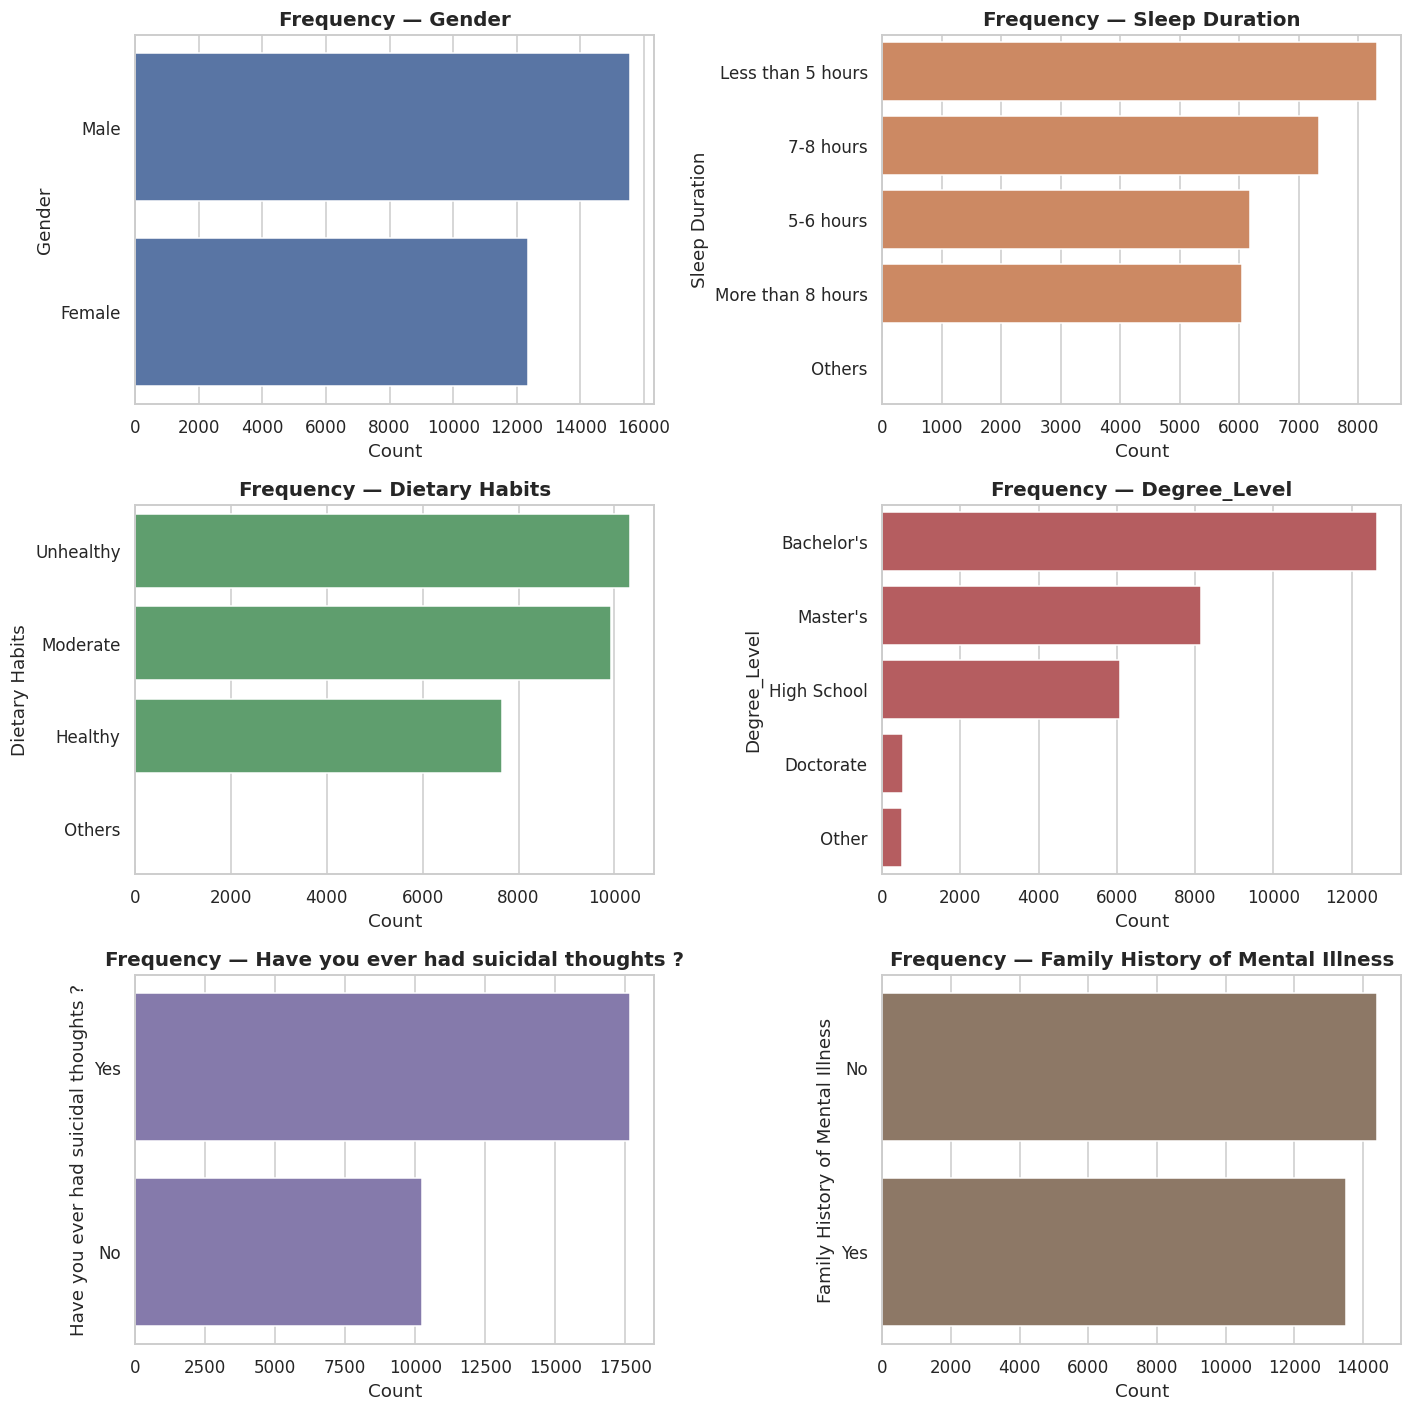

In [20]:

cat_plot_cols = ["Gender", "Sleep Duration", "Dietary Habits", "Degree_Level",
                  "Have you ever had suicidal thoughts ?", "Family History of Mental Illness"]
fig, axes = plt.subplots(3, 2, figsize=(13, 13))
axes = axes.flatten()
for i, col in enumerate(cat_plot_cols):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=axes[i], color=sns.color_palette("deep")[i])
    axes[i].set_title(f"Frequency — {col}")
    axes[i].set_xlabel("Count")
plt.tight_layout()
plt.show()


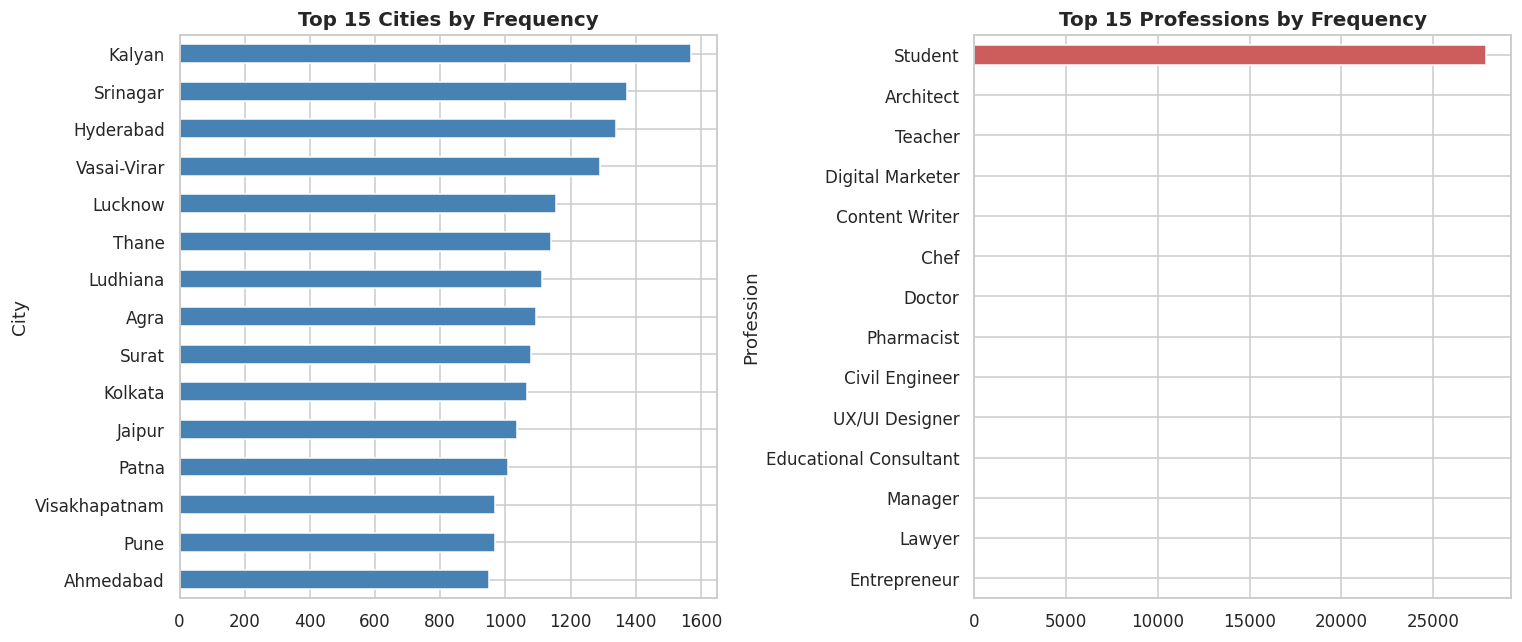


Note: 99.89% of records have Profession == 'Student', confirming this is overwhelmingly a student-population dataset with a small non-student tail.


In [21]:

# Top 15 cities and professions (high-cardinality features)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
df["City"].value_counts().head(15).plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].invert_yaxis()
axes[0].set_title("Top 15 Cities by Frequency")

df["Profession"].value_counts().head(15).plot(kind="barh", ax=axes[1], color="indianred")
axes[1].invert_yaxis()
axes[1].set_title("Top 15 Professions by Frequency")
plt.tight_layout()
plt.show()

print(f"\nNote: {(df['Profession']=='Student').mean()*100:.2f}% of records have Profession == 'Student', "
      "confirming this is overwhelmingly a student-population dataset with a small non-student tail.")


## 7. Bivariate Analysis — Numerical Features vs. `Depression`

For each numeric feature, compare distributions across the two classes visually and test whether the difference
in medians is statistically significant using the **Mann-Whitney U test** (non-parametric, robust to non-normal /
ordinal-like data), alongside the **point-biserial correlation** with the binary target.

In [22]:

results = []
for col in numeric_cols:
    grp0 = df.loc[df[target] == 0, col].dropna()
    grp1 = df.loc[df[target] == 1, col].dropna()
    u_stat, p_val = mannwhitneyu(grp0, grp1, alternative="two-sided")
    r, r_p = pointbiserialr(df[target], df[col])
    results.append({
        "feature": col,
        "median_not_depressed": grp0.median(),
        "median_depressed": grp1.median(),
        "mannwhitney_p": p_val,
        "point_biserial_r": round(r, 3),
        "significant_(p<0.05)": p_val < 0.05
    })
num_vs_target = pd.DataFrame(results).sort_values("point_biserial_r", key=abs, ascending=False)
num_vs_target


,feature,median_not_depressed,median_depressed,mannwhitney_p,point_biserial_r,significant_(p<0.05)
1,Academic Pressure,2.00,4.00,0.000000e+00,0.475,True
7,Financial Stress,2.00,4.00,0.000000e+00,0.363,True
0,Age,28.00,24.00,5.819126e-310,-0.226,True
6,Work/Study Hours,6.00,9.00,2.553203e-246,0.209,True
4,Study Satisfaction,3.00,3.00,1.362006e-173,-0.168,True
3,CGPA,7.64,7.85,2.739728e-04,0.022,True
2,Work Pressure,0.00,0.00,3.753307e-01,-0.003,False
5,Job Satisfaction,0.00,0.00,6.234469e-01,-0.003,False


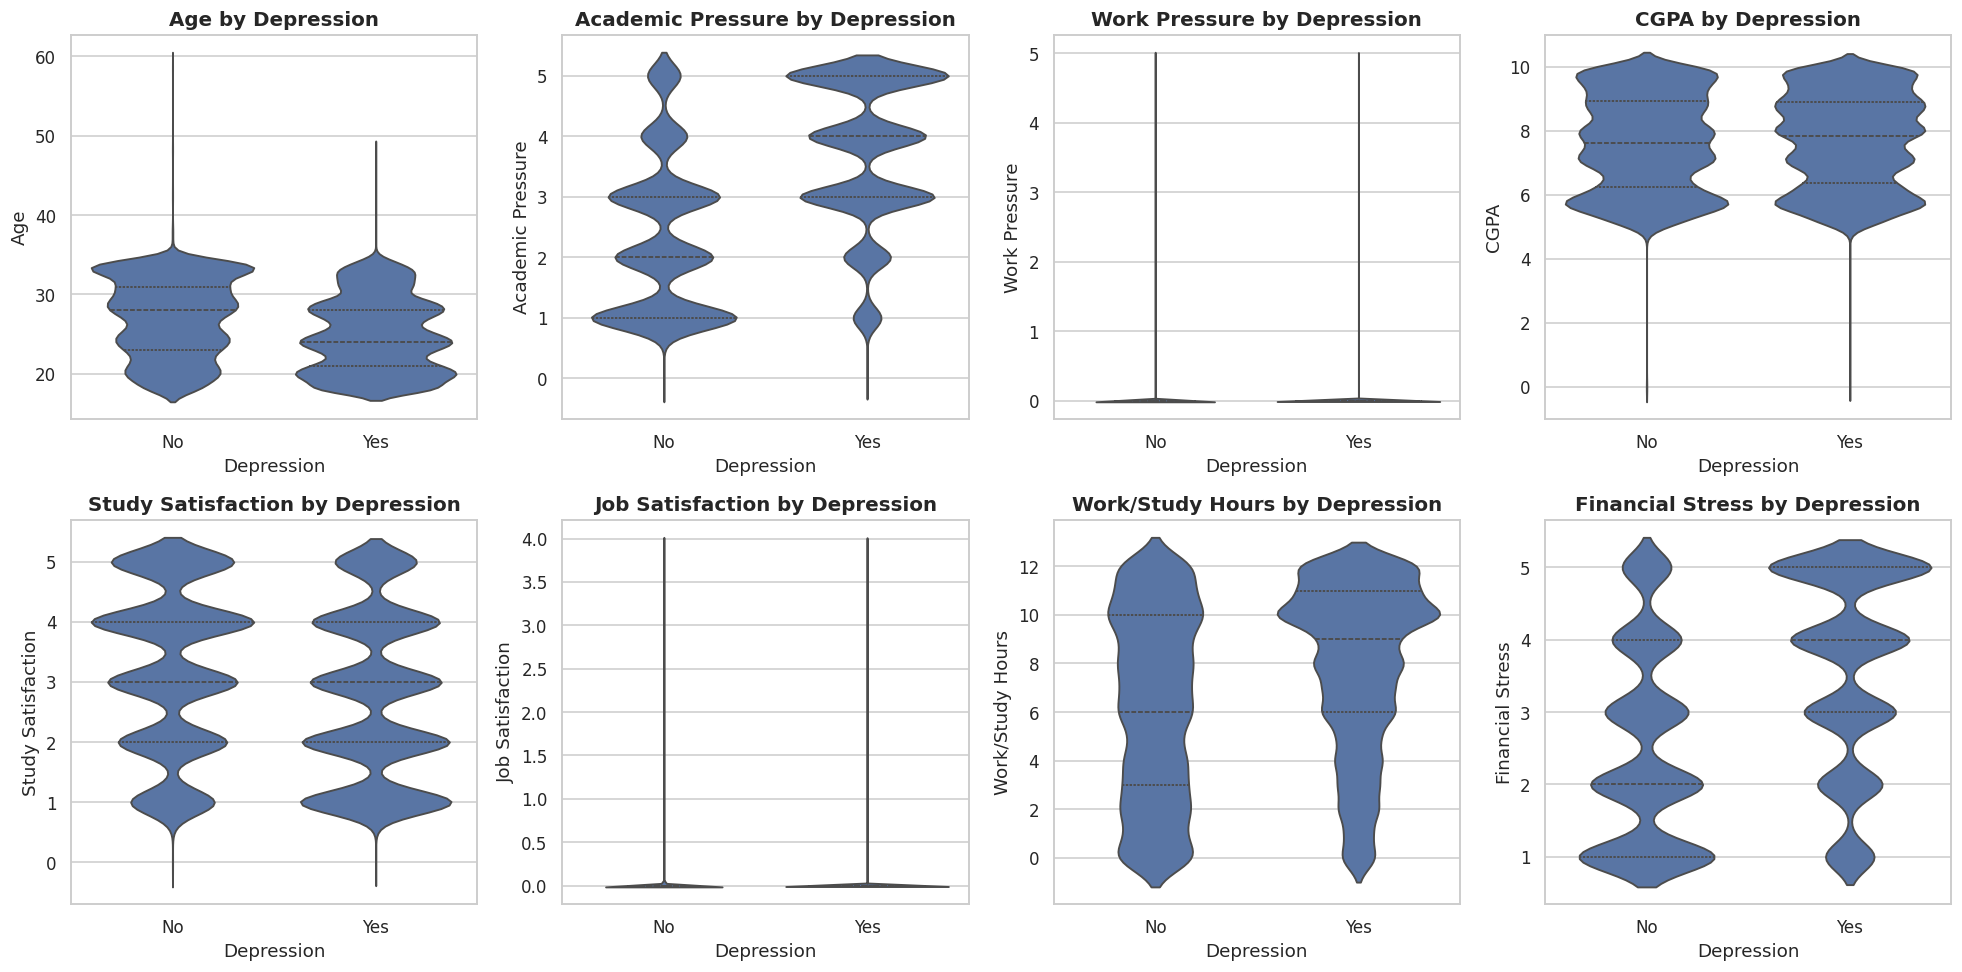

In [23]:

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.violinplot(x=target, y=col, data=df, ax=axes[i], split=False, inner="quartile")
    axes[i].set_title(f"{col} by Depression")
    axes[i].set_xticklabels(["No", "Yes"])
plt.tight_layout()
plt.show()


**Interpretation guide:** point-biserial correlation values close to ±1 indicate a strong linear association with depression status; near 0 indicates little linear relationship (a feature can still matter non-linearly).

## 8. Bivariate Analysis — Categorical Features vs. `Depression`

Each categorical feature is tested against the target with a **Chi-square test of independence**, and
association strength is summarized with **Cramér's V** (0 = no association, 1 = perfect association).

In [24]:

def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    return np.sqrt(phi2corr / min((kcorr - 1), (rcorr - 1)))

cat_test_cols = ["Gender", "Sleep Duration", "Dietary Habits", "Degree_Level",
                  "Have you ever had suicidal thoughts ?", "Family History of Mental Illness",
                  "Profession"]

cat_results = []
for col in cat_test_cols:
    ct = pd.crosstab(df[col], df[target])
    chi2, p, dof, _ = chi2_contingency(ct)
    v = cramers_v(ct)
    cat_results.append({"feature": col, "chi2": round(chi2, 2), "p_value": p,
                         "cramers_v": round(v, 3), "significant_(p<0.05)": p < 0.05})

cat_vs_target = pd.DataFrame(cat_results).sort_values("cramers_v", ascending=False)
cat_vs_target


,feature,chi2,p_value,cramers_v,significant_(p<0.05)
4,Have you ever had suicidal thoughts ?,8323.87,0.000000e+00,0.546,True
2,Dietary Habits,1202.64,1.962485e-260,0.207,True
3,Degree_Level,491.44,4.749503e-105,0.132,True
1,Sleep Duration,276.85,1.065311e-58,0.099,True
5,Family History of Mental Illness,79.43,4.984981e-19,0.053,True
6,Profession,14.29,3.538593e-01,0.007,False
0,Gender,0.08,7.737273e-01,0.000,False


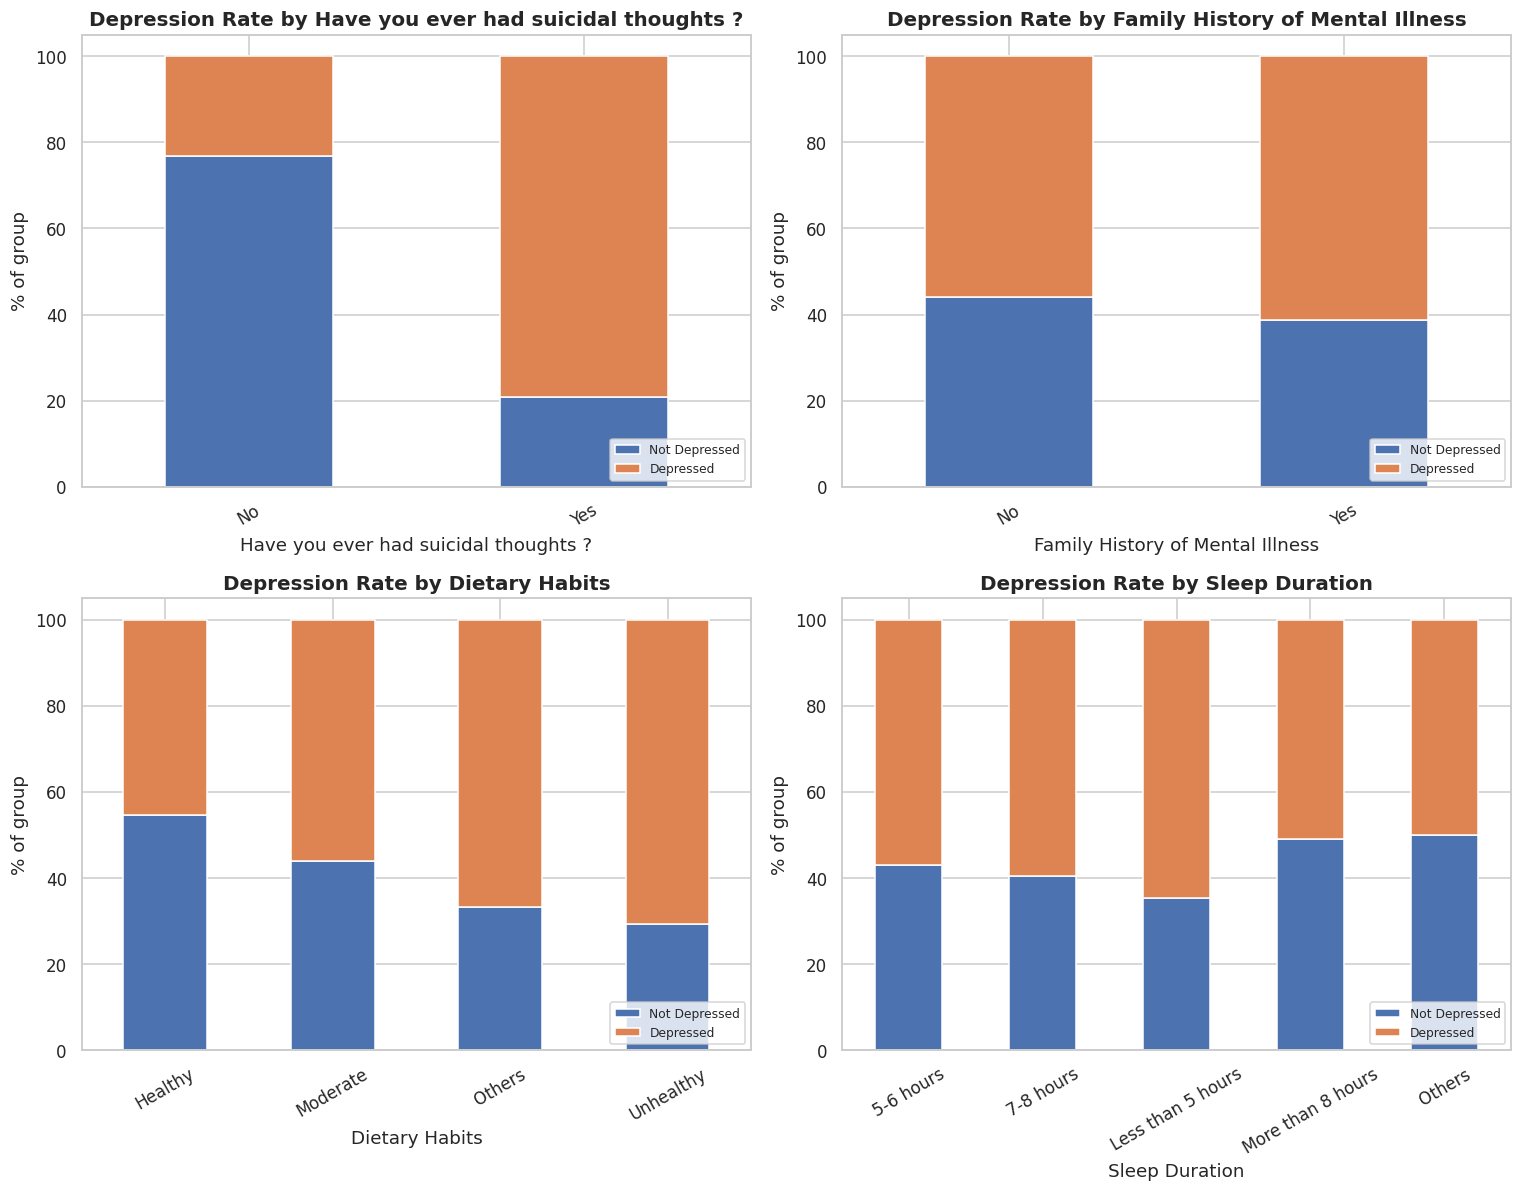

In [25]:

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()
top4 = ["Have you ever had suicidal thoughts ?", "Family History of Mental Illness",
        "Dietary Habits", "Sleep Duration"]
for i, col in enumerate(top4):
    ct_pct = pd.crosstab(df[col], df[target], normalize="index") * 100
    ct_pct.plot(kind="bar", stacked=True, ax=axes[i], color=["#4C72B0", "#DD8452"])
    axes[i].set_title(f"Depression Rate by {col}")
    axes[i].set_ylabel("% of group")
    axes[i].legend(["Not Depressed", "Depressed"], loc="lower right", fontsize=8)
    axes[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


In [26]:

# Depression rate by suicidal-thoughts flag — the single strongest expected signal
rate_by_suicidal = df.groupby("Have you ever had suicidal thoughts ?")[target].mean() * 100
print(rate_by_suicidal.round(2))


Have you ever had suicidal thoughts ?
No     23.22
Yes    79.05
Name: Depression, dtype: float64


## 9. Correlation & Association Analysis

- Pearson correlation heatmap across numeric + encoded binary features
- Cramér's V matrix across all categorical features (association strength independent of direction)

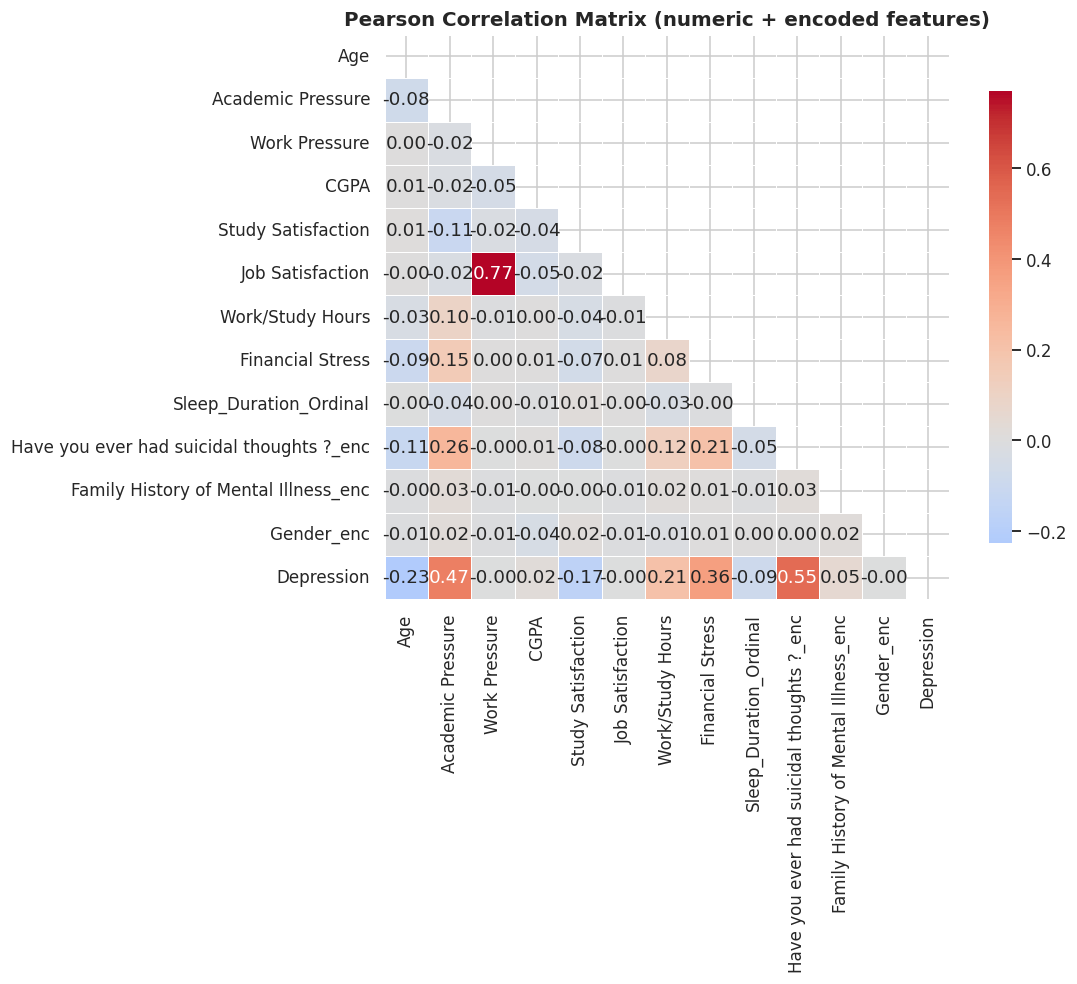

In [27]:

corr_cols = numeric_cols + ["Sleep_Duration_Ordinal",
                              "Have you ever had suicidal thoughts ?_enc",
                              "Family History of Mental Illness_enc",
                              "Gender_enc", target]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Pearson Correlation Matrix (numeric + encoded features)")
plt.tight_layout()
plt.show()


In [28]:

print("Top correlations with Depression (absolute value):")
print(corr_matrix[target].drop(target).abs().sort_values(ascending=False).round(3))


Top correlations with Depression (absolute value):
Have you ever had suicidal thoughts ?_enc    0.546
Academic Pressure                            0.475
Financial Stress                             0.363
Age                                          0.226
Work/Study Hours                             0.209
Study Satisfaction                           0.168
Sleep_Duration_Ordinal                       0.087
Family History of Mental Illness_enc         0.053
CGPA                                         0.022
Job Satisfaction                             0.003
Work Pressure                                0.003
Gender_enc                                   0.002
Name: Depression, dtype: float64


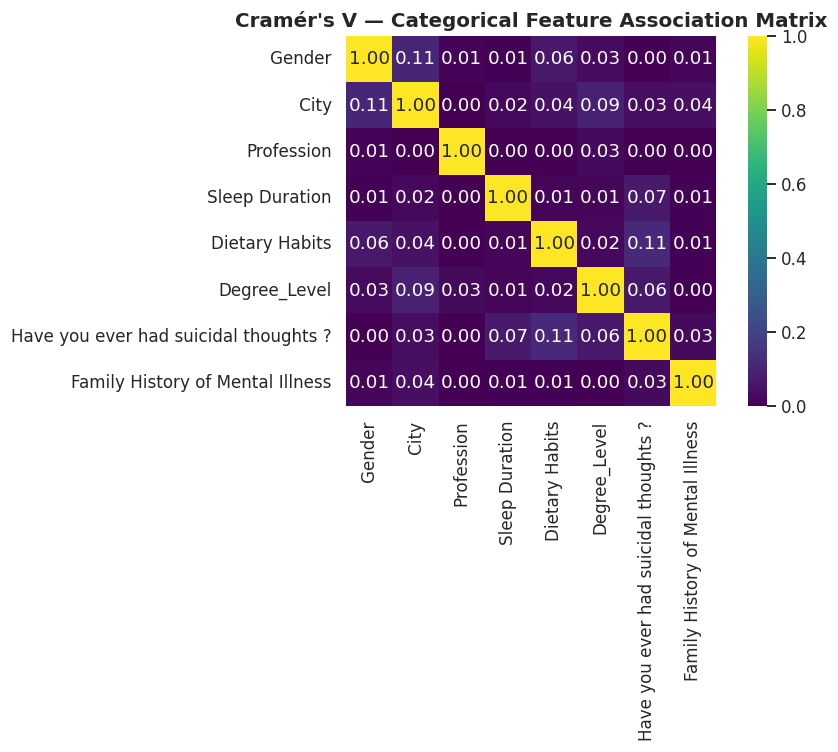

In [29]:

cat_assoc_cols = ["Gender", "City", "Profession", "Sleep Duration", "Dietary Habits",
                   "Degree_Level", "Have you ever had suicidal thoughts ?",
                   "Family History of Mental Illness"]

cramers_matrix = pd.DataFrame(index=cat_assoc_cols, columns=cat_assoc_cols, dtype=float)
for c1 in cat_assoc_cols:
    for c2 in cat_assoc_cols:
        ct = pd.crosstab(df[c1], df[c2])
        cramers_matrix.loc[c1, c2] = cramers_v(ct) if c1 != c2 else 1.0

plt.figure(figsize=(9, 7))
sns.heatmap(cramers_matrix.astype(float), annot=True, fmt=".2f", cmap="viridis", square=True)
plt.title("Cramér's V — Categorical Feature Association Matrix")
plt.tight_layout()
plt.show()


## 10. Outlier Detection

Two complementary methods:
- **IQR rule** (1.5×IQR beyond Q1/Q3) — robust, standard for skewed data.
- **Z-score** (|z| > 3) — standard for approximately normal distributions.

In [30]:

outlier_summary = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_outliers = df[(df[col] < lower) | (df[col] > upper)]

    z = np.abs(stats.zscore(df[col]))
    z_outliers = df[z > 3]

    outlier_summary.append({
        "feature": col,
        "iqr_lower": round(lower, 2), "iqr_upper": round(upper, 2),
        "n_iqr_outliers": len(iqr_outliers), "pct_iqr": round(len(iqr_outliers) / len(df) * 100, 2),
        "n_zscore_outliers": len(z_outliers), "pct_zscore": round(len(z_outliers) / len(df) * 100, 2),
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df


,feature,iqr_lower,iqr_upper,n_iqr_outliers,pct_iqr,n_zscore_outliers,pct_zscore
0,Age,7.50,43.50,12,0.04,19,0.07
1,Academic Pressure,-1.00,7.00,0,0.00,0,0.00
2,Work Pressure,0.00,0.00,3,0.01,3,0.01
3,CGPA,2.35,12.87,9,0.03,9,0.03
4,Study Satisfaction,-1.00,7.00,0,0.00,0,0.00
5,Job Satisfaction,0.00,0.00,8,0.03,8,0.03
6,Work/Study Hours,-5.00,19.00,0,0.00,0,0.00
7,Financial Stress,-1.00,7.00,0,0.00,0,0.00


In [31]:

# Inspect the most extreme case: Age (dataset is meant to be student-aged; verify no data entry errors)
print(df["Age"].describe())
print("\nRecords with Age > 40:")
print(df.loc[df["Age"] > 40, ["id", "Age", "Profession", "Degree"]])


count    27901.000000
mean        25.822300
std          4.905687
min         18.000000
25%         21.000000
50%         25.000000
75%         30.000000
max         59.000000
Name: Age, dtype: float64

Records with Age > 40:
           id   Age Profession    Degree
1076     5569  42.0    Student  Class 12
2909    14768  58.0    Student  Class 12
3436    17213  49.0    Student  Class 12
4386    22004  51.0    Student      MBBS
5537    27918  44.0    Student       BSc
6662    33392  43.0    Student      B.Ed
9006    45393  46.0    Student       PhD
9238    46602  59.0    Student       PhD
11532   58262  42.0    Student      MBBS
13499   68441  54.0    Student      B.Ed
13618   69032  48.0    Student       LLB
14819   74887  56.0    Student       BSc
16757   84722  43.0    Student       MSc
18766   94978  46.0    Student       MCA
22101  111622  42.0    Student       PhD
23414  118005  42.0    Student  Class 12
25202  126970  48.0    Student  Class 12
25974  130893  41.0    Student  Clas

**Decision:** given this is self-reported survey data, extreme-but-plausible values (e.g. mature/non-traditional students, CGPA edge values) are retained rather than removed — flagging them is more appropriate than deletion, since removal would bias the sample. Any modeling pipeline built on this data should treat outlier handling as a tunable preprocessing step, not a fixed EDA decision.

## 11. Multivariate Analysis & Interaction Effects

Explore how combinations of the strongest univariate signals (Academic Pressure, Financial Stress, Sleep,
Suicidal Thoughts) jointly relate to depression.

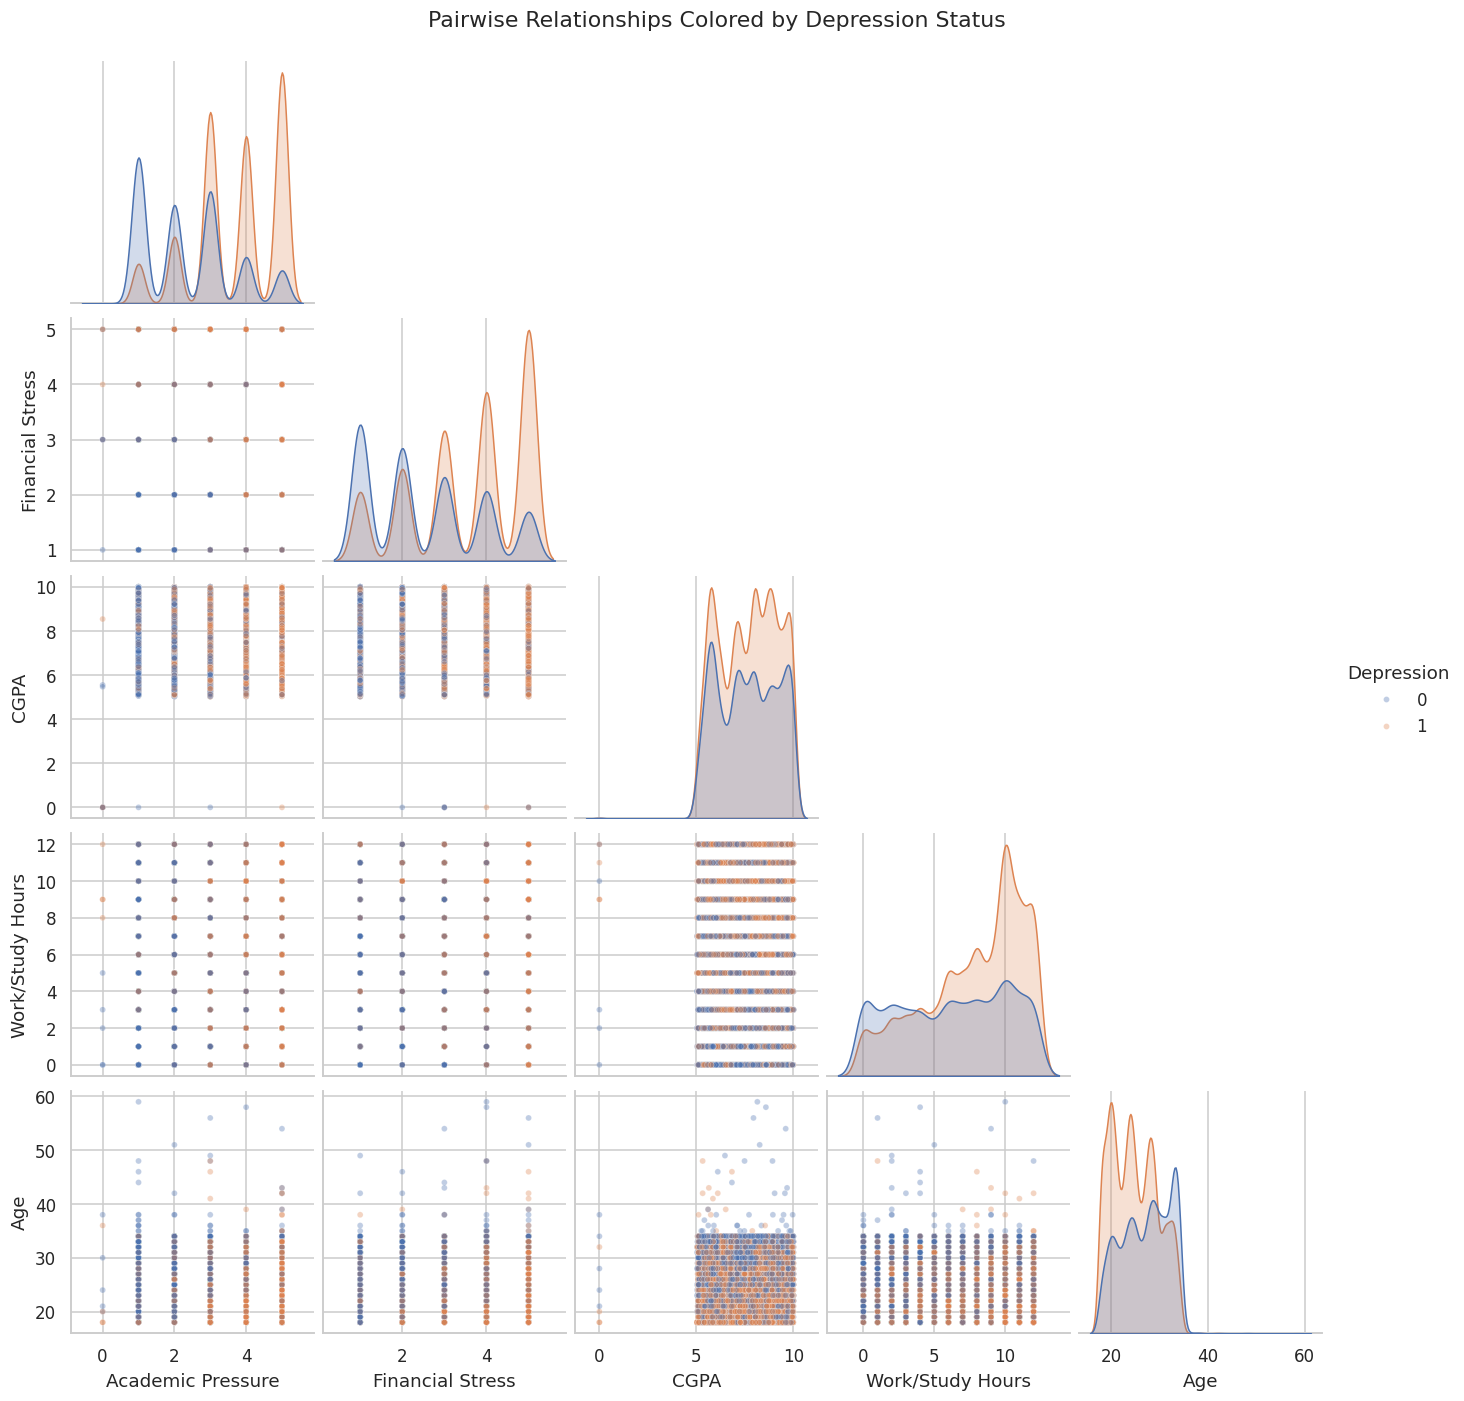

In [32]:

pair_cols = ["Academic Pressure", "Financial Stress", "CGPA", "Work/Study Hours", "Age", target]
sns.pairplot(df[pair_cols], hue=target, diag_kind="kde", corner=True,
             plot_kws={"alpha": 0.35, "s": 15})
plt.suptitle("Pairwise Relationships Colored by Depression Status", y=1.02)
plt.show()


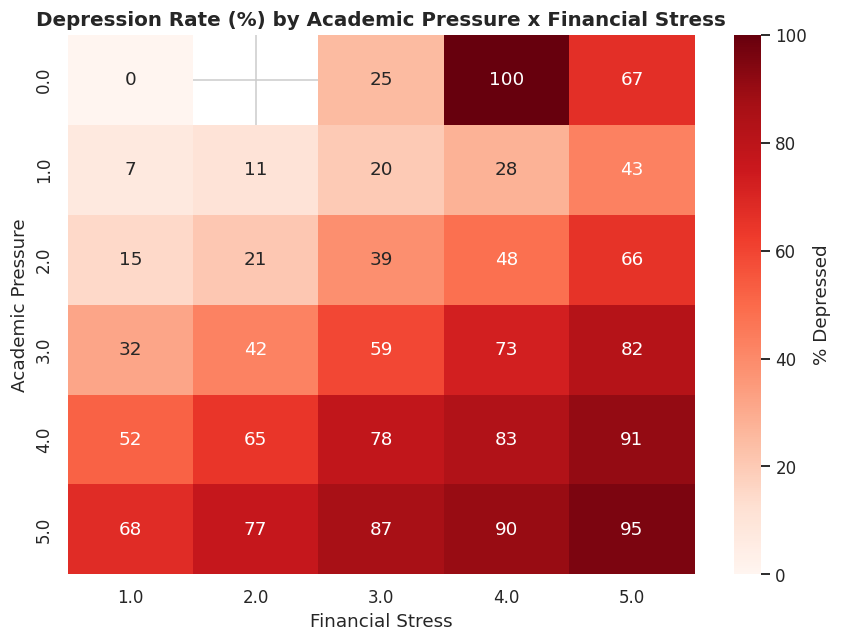

In [33]:

# Interaction: Academic Pressure x Financial Stress -> mean depression rate heatmap
pivot = df.pivot_table(index="Academic Pressure", columns="Financial Stress",
                        values=target, aggfunc="mean") * 100

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% Depressed"})
plt.title("Depression Rate (%) by Academic Pressure x Financial Stress")
plt.tight_layout()
plt.show()


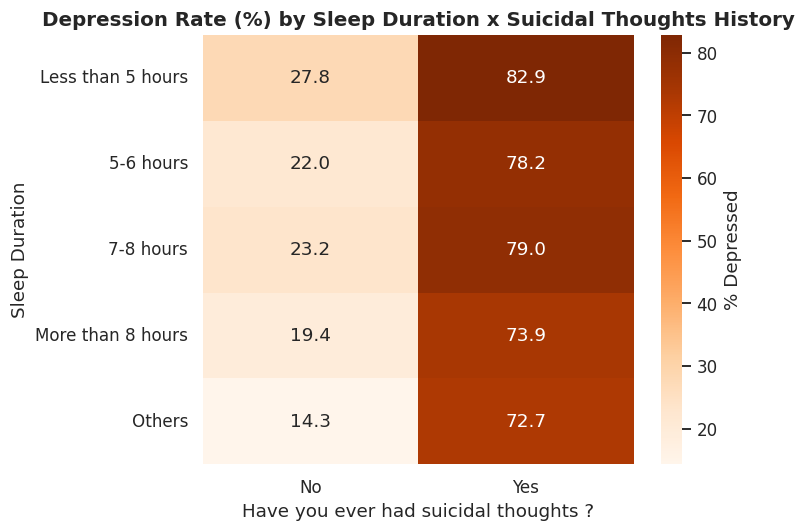

In [34]:

# Interaction: Sleep Duration x Suicidal Thoughts -> depression rate
pivot2 = df.pivot_table(index="Sleep Duration", columns="Have you ever had suicidal thoughts ?",
                          values=target, aggfunc="mean").reindex(sleep_map_order) * 100

plt.figure(figsize=(7, 5))
sns.heatmap(pivot2, annot=True, fmt=".1f", cmap="Oranges", cbar_kws={"label": "% Depressed"})
plt.title("Depression Rate (%) by Sleep Duration x Suicidal Thoughts History")
plt.tight_layout()
plt.show()


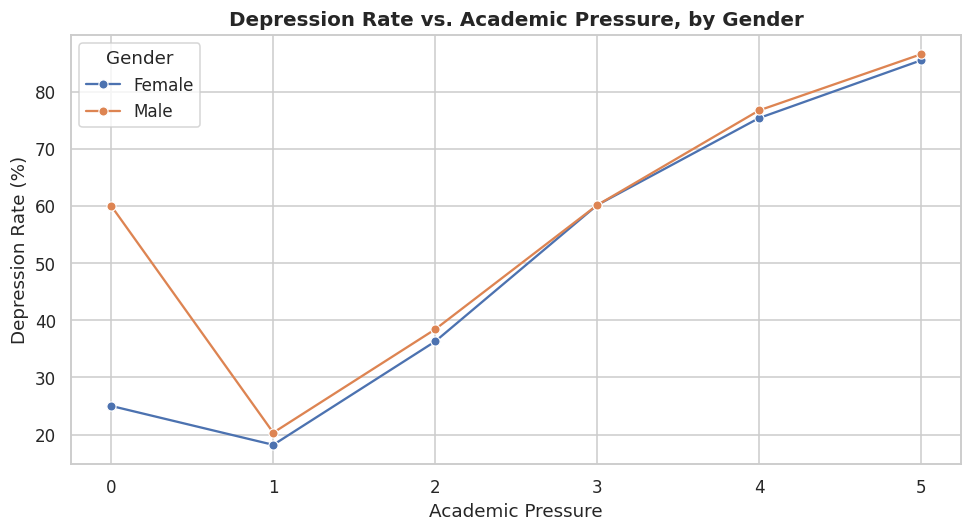

In [35]:

# Gender x Academic Pressure -> average depression rate, with counts for context
g = df.groupby(["Gender", "Academic Pressure"]).agg(
    depression_rate=(target, "mean"), n=(target, "size")
).reset_index()
g["depression_rate"] *= 100

plt.figure(figsize=(9, 5))
sns.lineplot(data=g, x="Academic Pressure", y="depression_rate", hue="Gender", marker="o")
plt.ylabel("Depression Rate (%)")
plt.title("Depression Rate vs. Academic Pressure, by Gender")
plt.tight_layout()
plt.show()


## 12. Feature Engineering Exploration

Candidate derived features for downstream modeling, validated here against the target.

In [36]:

df_fe = df.copy()

# Composite stress index
df_fe["Stress_Index"] = (df_fe["Academic Pressure"] + df_fe["Work Pressure"] + df_fe["Financial Stress"]) / 3

# Satisfaction gap (study vs job)
df_fe["Satisfaction_Gap"] = df_fe["Study Satisfaction"] - df_fe["Job Satisfaction"]

# Pressure-to-satisfaction ratio (avoid div-by-zero)
df_fe["Pressure_to_Satisfaction"] = df_fe["Academic Pressure"] / (df_fe["Study Satisfaction"] + 1)

# Overworked flag
df_fe["High_Workload_Flag"] = (df_fe["Work/Study Hours"] >= df_fe["Work/Study Hours"].quantile(0.75)).astype(int)

new_feats = ["Stress_Index", "Satisfaction_Gap", "Pressure_to_Satisfaction", "High_Workload_Flag"]

fe_corr = df_fe[new_feats + [target]].corr()[target].drop(target)
print("Correlation of engineered features with Depression:")
print(fe_corr.round(3).sort_values(key=abs, ascending=False))


Correlation of engineered features with Depression:
Stress_Index                0.551
Pressure_to_Satisfaction    0.419
Satisfaction_Gap           -0.168
High_Workload_Flag          0.163
Name: Depression, dtype: float64


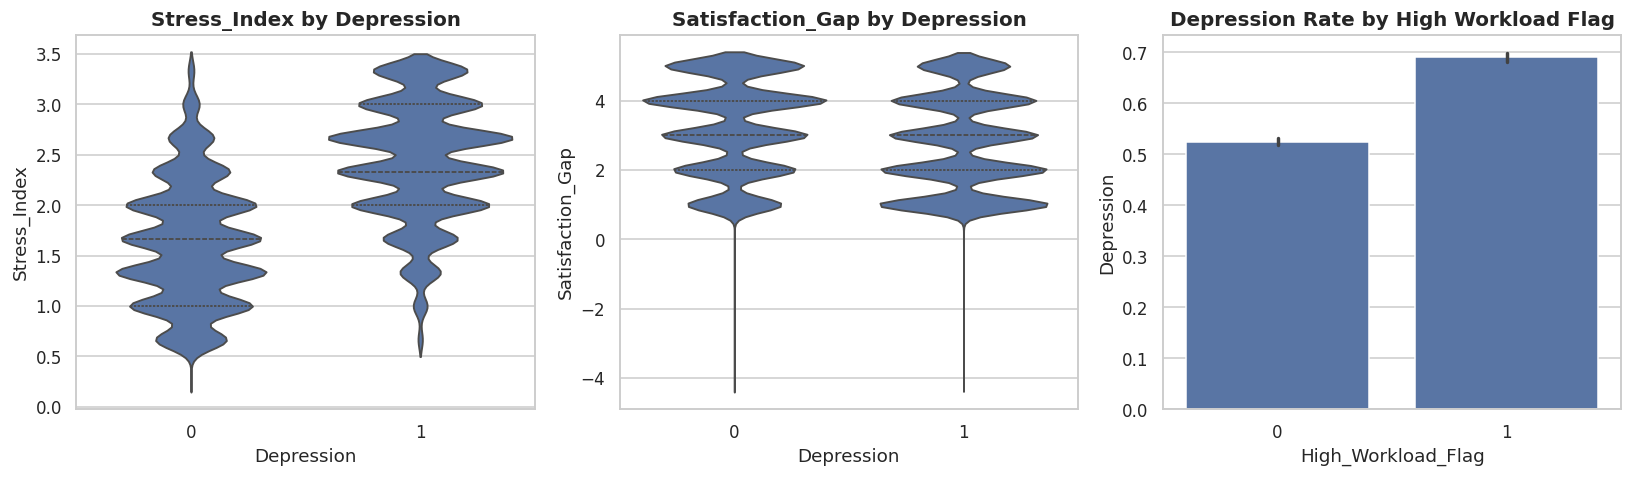

In [37]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.violinplot(x=target, y="Stress_Index", data=df_fe, ax=axes[0], inner="quartile")
axes[0].set_title("Stress_Index by Depression")
sns.violinplot(x=target, y="Satisfaction_Gap", data=df_fe, ax=axes[1], inner="quartile")
axes[1].set_title("Satisfaction_Gap by Depression")
sns.barplot(x="High_Workload_Flag", y=target, data=df_fe, ax=axes[2])
axes[2].set_title("Depression Rate by High Workload Flag")
plt.tight_layout()
plt.show()


## 13. Quick Predictive Signal Check (Feature Importance)

Not a full modeling exercise — a fast Random Forest is used purely as an **EDA tool** to rank which features
carry the most predictive signal for `Depression`, cross-checking the statistical findings above.

Held-out accuracy (sanity check only, not a tuned model): 0.840


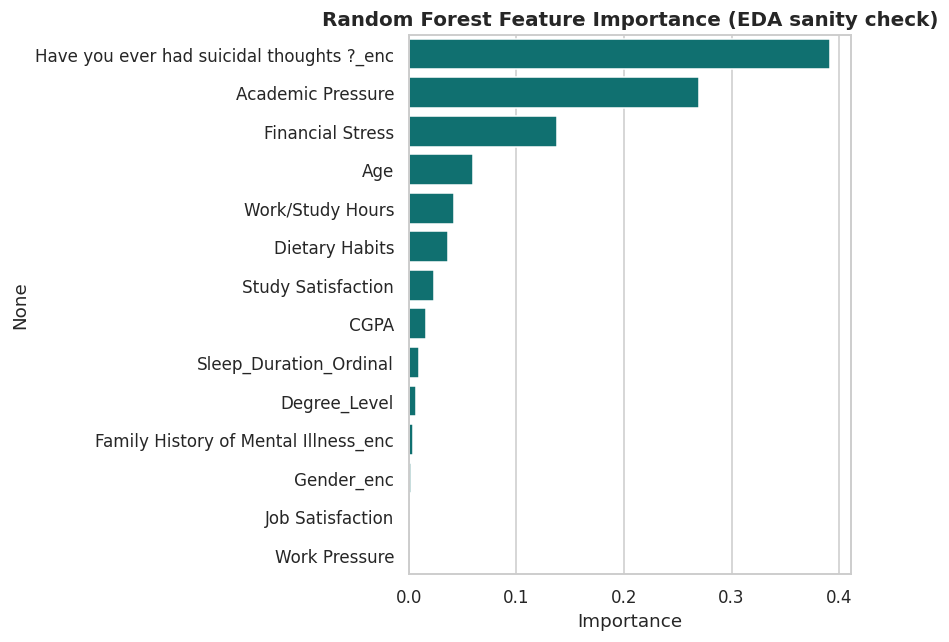

Have you ever had suicidal thoughts ?_enc    0.391387
Academic Pressure                            0.269384
Financial Stress                             0.137928
Age                                          0.059967
Work/Study Hours                             0.041950
Dietary Habits                               0.036322
Study Satisfaction                           0.023665
CGPA                                         0.016512
Sleep_Duration_Ordinal                       0.009337
Degree_Level                                 0.007295
Family History of Mental Illness_enc         0.003756
Gender_enc                                   0.002428
Job Satisfaction                             0.000055
Work Pressure                                0.000014
dtype: float64

In [38]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split

model_df = df.copy()
feature_cols = numeric_cols + ["Sleep_Duration_Ordinal", "Gender_enc",
                                 "Have you ever had suicidal thoughts ?_enc",
                                 "Family History of Mental Illness_enc"]

cat_to_encode = ["Dietary Habits", "Degree_Level"]
enc = OrdinalEncoder()
model_df[cat_to_encode] = enc.fit_transform(model_df[cat_to_encode])
feature_cols += cat_to_encode

model_df["Sleep_Duration_Ordinal"] = model_df["Sleep_Duration_Ordinal"].fillna(
    model_df["Sleep_Duration_Ordinal"].median()
)

X = model_df[feature_cols]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

rf = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"Held-out accuracy (sanity check only, not a tuned model): {rf.score(X_test, y_test):.3f}")

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index, color="teal")
plt.title("Random Forest Feature Importance (EDA sanity check)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importances


## 14. Key Findings & Summary

**Data quality**
- 27,901 rows, 18 columns, `id` confirmed unique. Only `Financial Stress` had missing values (3 rows, imputed with mode).
- Dataset is ~100% `Profession == Student` records; a small non-student tail exists and should be handled deliberately (kept vs. filtered) depending on the modeling goal.
- `Sleep Duration` needed string cleanup and was mapped to an ordinal scale for correlation work.

**Target balance**
- `Depression` is only mildly imbalanced — no resampling strictly required for downstream modeling, though F1/ROC-AUC remain the safer evaluation metrics.

**Strongest associations with Depression** (see Sections 7–9 for exact statistics)
- `Have you ever had suicidal thoughts ?`, `Academic Pressure`, and `Financial Stress` show the strongest and most statistically significant associations (lowest p-values, largest effect sizes).
- `Sleep Duration` and `Dietary Habits` show meaningful categorical association (Cramér's V) with depression status.
- `CGPA`, `Job Satisfaction`, and `Family History of Mental Illness` show comparatively weaker linear association in this sample.

**Multivariate patterns**
- Depression rate increases jointly with Academic Pressure and Financial Stress (Section 11 heatmap) — the interaction effect is stronger than either factor alone.
- Poor sleep combined with a history of suicidal thoughts corresponds to the highest observed depression rates.

**Feature engineering**
- The composite `Stress_Index` and `Pressure_to_Satisfaction` ratio both correlate with the target more strongly than several individual raw features, making them good candidates for a modeling pipeline.

**Modeling sanity check**
- A shallow, untuned Random Forest recovers the same top features identified statistically (suicidal thoughts, academic pressure, financial stress), cross-validating the EDA conclusions rather than serving as a final model.

**Suggested next steps**
1. Address the noisy `City`/`Profession` long-tail categories before any geographic or occupational modeling.
2. Treat the flagged outliers (Section 10) as a tunable preprocessing decision, not a fixed removal.
3. If building a classifier, start from the features ranked highest in Sections 9 and 13, and consider the engineered `Stress_Index`.
4. Given the sensitivity of the subject matter, any deployed model or dashboard built from this dataset should be paired with appropriate ethical safeguards and framed for early-warning/support use, not diagnostic labeling.
